In [1]:
import numpy as np   
import matplotlib.pyplot as plt  

<h1>2.51</h1>

<h2>Bisection Method</h2>
<h3>Repeatedly dividing an interval in half and pick up sub-intervals where a root exists until find the approximated root.</h3>

0. Ensure that the given function is continuous and has at least one root between the given endpoints of the interval.
1. Start with an initial interval $[a, b]$ where $f(a)$ and $f(b)$ have opposite values, which implies that there exists a root in the interval by the Intermediate Value Theorem (IVT).
2. Compute the midpoint $m = \frac{a+b}{2}$.
3. Check the function value $f(m)$. If $f(m)=0$, or if it is small enough to close to zero (within the tolerance), then the $m$ is the approximated root.
4. If $f(m)$ is not the approximated root, then determine if $f(m)\cdot f(a) < 0$, and then replace the interval endpoint $b$ with $m$ since we can ensure that the function values $f(m)$ and $f(a)$ have opposite values, or replace $a$ with $m$ if $f(m)\cdot f(b) < 0$.
5. Repeat step 2 to 4 until the root is approximated to the desired accuracy.

In [2]:
def bisection(f, a, b, tol):
    if f(a)*f(b)>0: #Ensure that the endpoints have opposite values
        raise ValueError("The provided endpoints have the same sign so that we cannot guarantee a root exists between them")
    
    while b-a >tol:
        m = (a+b)/2 #midpoint
        
        if f(m) == 0 or np.abs(f(m))<tol:
            return m
        
        elif f(a)*f(m)<0:
            b=m 
        elif f(m)*f(b)<0:
            a=m 
    
    m = (a+b)/2 # update the root 
    
    return m    
    

<h1>2.52</h1>

<h2>Regula Falsi Method</h2>
<h3>Taking a point from a given interval, where is the intersection of the x-axis and the connection line passing through endpoints, until the root is approximated.</h3>

0. Ensure that the function is continuous and there exists at least on root within the given interval.
1. Similar to Bisection Method, start with an initial interval $[a, b]$, where $f(a)$ and $f(b)$ have opposite signs.
2. Calculate the intersection $c$ of the x-axis and the straight line connecting points $(a, f(a))$ and $(b, f(b))$. The formula is $c = a - \frac{(b-a) f(a)}{f(b)-f(a)}$.
3. Check the function value $f(c)$. If $f(c) = 0$ or it is sufficiently close to zero, $c$ is the approximated root.
4. If $f(c)$ is not small enough to zero, replace $b$ with $c$ if $f(m)\cdot f(a) < 0$, or replace $a$ with $c$ if $f(m)\cdot f(b) < 0$.
5. Repeat step 2 to 4 until the approximated root is found within a desired tolerance.

In [3]:
def regulafalsi(f, a, b, tol):
    if np.sign(f(a))==np.sign(f(b)): # Check to ensure opposite signs 
        raise ValueError("Selected endpoints have the same sign, so we cannot ensure there exists a root between them")
    
    while b-a > tol:
        c = a - ((b-a)*f(a))/(f(b)-f(a)) #intersection 
        
        if f(c) == 0 or np.abs(f(c))<tol:
            return c
        
        elif f(a)*f(c)<0:
            b=c 
        elif f(c)*f(b)<0:
            a=c  
    
    return c    
        

<h1>2.53</h1>

<h2>Newton's Method</h2>
<h3>Updating an appropriate tangent line of the continuous function to find approximations to the root.</h3>

0. Ensure that the given real-valued function is continuous and its first derivative $f'(x)$ is not zero, and there exists at least one root.
1. Start with an initial guess $x_0$, as close to the root as possible.
2. Calculate the next approximation $x_1$ with the formula of $x_1 = x_0 - \frac{f(x_0)}{f'(x_0)}$. In general, $x_{n+1} = x_n - \frac{f(x_n)}{f'(x_n)}$.
3. If $f(x_1)$ is zero or close enough to zero, then $x_1$ is the approximated root.
4. If $x_1$ is not the approximated root within the desired accuracy, then update the next approximation.
5. Repeat step 2 to 4 until the root is approximated within the desired tolerance.


In [4]:
def newton(f, df, x0, tol):
    x = x0
    
    while np.abs(f(x))>tol:
        
        f_x=f(x)
        df_x=df(x)
    
        if df_x == 0:
            raise ValueError("The first derivative of the given function is 0, fail to execute Newton's Method.")
        
        x_new = x - f_x/df_x #update approximations
        
        x = x_new
    
    return x
        

<h1>2.54</h1>

<h2>Secant Method</h2>
<h3>Using secant lines to approximate the root of a real-valued function, and it is similar to Newton's Method but does not require the function's first derivative.</h3>

0. Ensure that the given function is continuous and has at least one root.
1. Start with 2 initial guesses $x_0$ and $x_1$.
2. Calculate the nex approximation $x_2$ with the formula of $x_2 = x_1 - \frac{f(x_1)\cdot (x_1-x_0)}{f(x_1)-f(x_0)}$. In general, $x_{n+1} = x_n - \frac{f(x_n)\cdot (x_n-x_{n-1})}{f(x_n)-f(x_{n-1})}$.
3. If $f(x_2)$ is zero or close enough to zero, then $x_2$ is the approximated root.
4. If $x_2$ is not the approximated root within the desired accuracy, then update the next approximation.
5. Repeat step 2 to 4 until the approximated root is found with the desired tolerance.

In [5]:
def secant(f, x0, x1, tol):
    
    while np.abs(f(x1)-f(x0))>tol:
        f_x0 = f(x0)
        f_x1 = f(x1)
        
        if np.abs(f_x1 - f_x0) == 0:
            raise Exception("Please choose 2 different point to form a secant line.")
        
        
        x_new = x1 - (f_x1 * (x1-x0))/(f_x1 - f_x0) #Update the approximations
        
        x0, x1 = x1, x_new
    
    return x_new

<h1>2.57</h1>

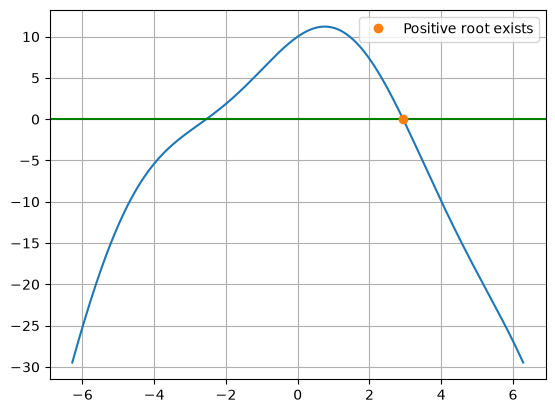

In [6]:
def f(x):
    return 3*np.sin(x) + 9 - x**2 + np.cos(x)

def df(x):
    return 3*np.cos(x) + 0 - 2*x - np.sin(x)
 
x = np.linspace(-2*np.pi, 2*np.pi, 400)
plt.plot(x, f(x))
plt.axhline(0, color = "green")
plt.grid(True)
plt.plot(2.93, 0, "o", label="Positive root exists")
plt.legend()
plt.show()

In [7]:
root_1 = bisection(f, -3, -2, 1e-10)
root_2 = bisection(f, 2, 3, 1e-10)
print(f"By using Bisection Method with 1e-10 accuracy, the positive root is approximated as {root_2}.")

By using Bisection Method with 1e-10 accuracy, the positive root is approximated as 2.93748720511212.


In [8]:
root_1 = regulafalsi(f, -3, -2, 1e-10)
root_2 = regulafalsi(f, 1.5, 3, 1e-10)
print(f"By using Regula Falsi Method with 1e-10 accuracy, the positive root is approximated as {root_2}.")

By using Regula Falsi Method with 1e-10 accuracy, the positive root is approximated as 2.9374872051077756.


In [9]:
root_1 = newton(f, df, -3, 1e-10)
root_2 = newton(f, df, 2, 1e-10)
print(f"By using Newton's Method with 1e-10 accuracy, the positive root is approximated as {root_2}.")

By using Newton's Method with 1e-10 accuracy, the positive root is approximated as 2.9374872051080065.


In [10]:
root_1 = secant(f, -3, -2, 1e-10)
root_2 = secant(f, 2, 2.1, 1e-10)
print(f"By using Secant Method with 1e-10 accuracy, the positive root is approximated as {root_2}.")

By using Secant Method with 1e-10 accuracy, the positive root is approximated as 2.937487205107865.


<h1>2.63</h1>

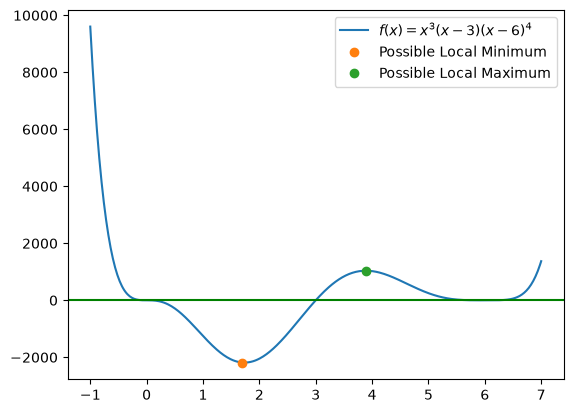

In [11]:
def f(x):
    return x**3 * (x-3) * (x-6)**4

def df(x):
    return x**3*(x - 6)**4 + 4*x**3*(x - 6)**3*(x - 3) + 3*x**2*(x - 6)**4*(x - 3)

def d2f(x):
    return 8*x**3*(x - 6)**3 + 12*x**3*(x - 6)**2*(x - 3) + 6*x**2*(x - 6)**4 + 24*x**2*(x - 6)**3*(x - 3) + 6*x*(x - 6)**4*(x - 3)

# Check possible positions of extrema
x = np.linspace(-1, 7, 400)
plt.plot(x, f(x), label="$f(x) = x^3 (x-3) (x-6)^4$")
plt.axhline(0, color="green")
plt.plot(1.7, f(1.7), "o", label = "Possible Local Minimum")
plt.plot(3.9, f(3.9), "o", label="Possible Local Maximum")
plt.legend()
plt.show()

In [12]:
def Newton(df, d2f, x, tol):
    x = x

    while np.abs(df(x)) > tol:
        df_x = df(x)
        d2f_x = d2f(x)
        
        if d2f(x) == 0 or np.abs(d2f(x)) < tol:
            raise Exception("The second derivative at the given point is close to zero, so cannot execute Newton's Method.")
        
        x = x - df_x/d2f_x
        
    return x, f(x)


local_min, min_value = Newton(df, d2f, 2, 1e-5)
print(f"By using Newton's Method, the local minimum is found at x = {local_min} with the function value of {min_value}.")

local_max, max_value = Newton(df, d2f, 4, 1e-5)
print(f"By using Newton's Method, the local maximum is found at x = {local_max} with the function value of {max_value}.")

###################################################################################################
local_max, max_value = Newton(df, d2f, -1, 1e-5)
print(f"\nBy using Newton's Method, the local maximum is found at x = {local_max} with the function value of {max_value}.")

local_min, min_value = Newton(df, d2f, 7, 1e-5)
print(f"By using Newton's Method, the local minimum is found at x = {local_min} with the function value of {min_value}.")

By using Newton's Method, the local minimum is found at x = 1.7353945037739733 with the function value of -2186.0755510076497.
By using Newton's Method, the local maximum is found at x = 3.889605495994573 with the function value of 1038.4096408232656.

By using Newton's Method, the local maximum is found at x = -2.0911991213624167e-05 with the function value of 3.5556704419197216e-11.
By using Newton's Method, the local minimum is found at x = 6.0015603823981944 with the function value of 3.846482800600961e-09.


<h1>2.65</h1>

<h2>a.-b.</h2>

The root is approximated at (array([2.76492175]), {'nfev': 10, 'fjac': array([[-1.]]), 'r': array([2.56493214]), 'qtf': array([1.10844667e-12]), 'fvec': array([0.])}, 1, 'The solution converged.')


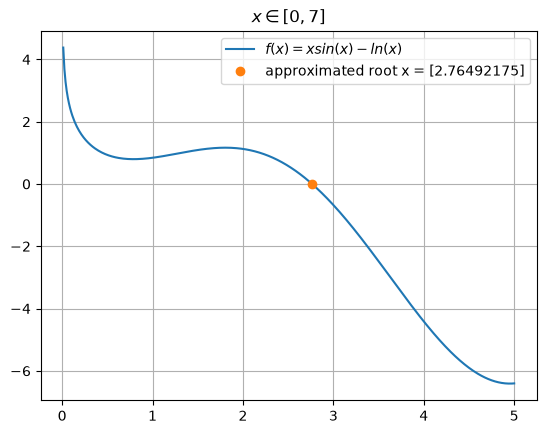

In [13]:
import scipy as sp 

f = lambda x: x*np.sin(x) - np.log(x)

x = np.linspace(0, 5, 400)
plt.plot(x, f(x), label = "$f(x) =  xsin(x) - ln(x)$")
plt.grid(True)
plt.title(r"$x \in [0, 7]$")


x0 = 3
root = sp.optimize.fsolve(f, x0, full_output=1) # using fsolve() in scipy.optimize
print(f"The root is approximated at {root}")

plt.plot(root[0], 0, "o", label = f"approximated root x = {root[0]}")

plt.legend()
plt.show()


The output of fsolve() with full_output=1 is (array([2.76492175]), {'nfev': 8, 'fjac': array([[-1.]]), 'r': array([2.56493214]), 'qtf': array([1.10844667e-12]), 'fvec': array([0.])}, 1, 'The solution converged.')<br>

The first element is the array of the roots we find, under this case, there exists one approximated root at x = 2.76492175.<br>

The second element is a dictionary of optional outputs with the keys:<br>
'nfev' of 8 means 8 function evaluations<br>
'fjac' of an array of -1 is the number of Jacobian calls<br>
'r' is an array contained the upper triangular matrix produced by the OR decomposition of the final approximate Jacobian matrix, and is stored row-wise<br>
'qtf' represent the vector of transpose(q) * fvec, <br>
where 'fvec' is the function value at solution of 0 in this case.<br>
 
The third element number 1 means an int that represents a root has been found. <br>

The fourth element relates to the third one, which indicates a message describing the outcome. Under this case, the solution is converged and we find the root.



<h2>c.<h2>

The root is found at x =(array([0.31492306]), {'nfev': 9, 'fjac': array([[-1.]]), 'r': array([-3.37015098]), 'qtf': array([-3.29413785e-09]), 'fvec': array([-2.88657986e-15])}, 1, 'The solution converged.')


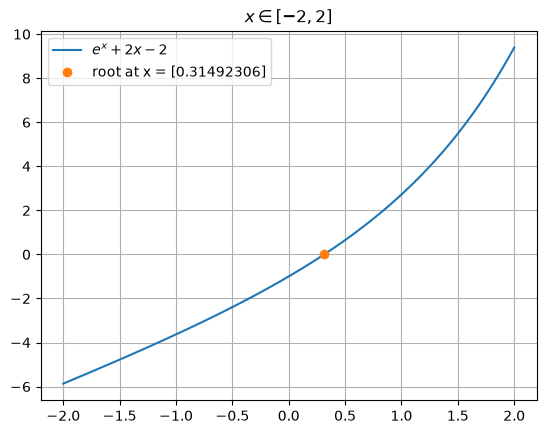

In [14]:
# select one non-trivial nonlinear equation:
# e^x + 2x - 2 = 0

def f(x):
    return np.exp(x) + 2*x -2 

x = np.linspace(-2, 2, 400)
plt.plot(x, f(x), label="$e^x + 2x - 2$")
plt.title(r"$x \in [-2, 2]$")
plt.grid(True)

# using fsolve() for root-finding
non_trivial_root = sp.optimize.fsolve(f, 0, full_output = 1)
print(f"The root is found at x ={non_trivial_root}")

plt.plot(non_trivial_root[0], 0, "o", label = f"root at x = {non_trivial_root[0]}")

plt.legend()
plt.show()


Set up $e^x + 2x - 2 = 0$ <br>

Using fsolve() for this non-trivial nonlinear equation, and the equation is solved with the approximated root at x = 0.31492306. The solution is converged where is indicated by the message of 'The solution converged."<br>

fsolve() evaluates the given function 7 times and the [-1] is the Jacobian matrix of the function at the root. THe upper triangular matrix from the QR decomposition of the final approximate Jacobian matrix is returned as a one-dimensional array of [-3.37015098]. The vector of transpose(q) * fvec is -2.88657986e-15, which is close to 0. and 'fvec' returns the int of 1 which indicates that the root has been found.<br>

The example demonstrates that we use fsolve() to approximate a root for a more complex function and it is useful for solving nonlinear equations which are difficult to be solved by hands.


<h2>d.</h2>

In [15]:
from scipy.optimize import fsolve


# Given by the textbook
def F(x):
  Output = [ x[0]*np.cos(x[1])-4 ]
  Output.append( x[0]*x[1] - x[1] - 5 )
  return Output

# Or alternately we could define the system as a lambda function 
# with F = lambda x: [ x[0]*np.cos(x[1])-4 , x[0]*x[1]-x[1]-5 ]

fsolve(F,[6,1],full_output=1) 
# Note: full_output gives the solver diagnostics


(array([6.50409711, 0.90841421]),
 {'nfev': 11,
  'fjac': array([[-0.55345956, -0.83287605],
         [ 0.83287605, -0.55345956]]),
  'r': array([-1.10094528, -1.74086803, -7.30631344]),
  'qtf': array([-4.69150245e-10, -1.12803750e-09]),
  'fvec': array([ 3.64153152e-14, -5.41788836e-14])},
 1,
 'The solution converged.')

In [16]:
# try different initial guesses
fsolve(F, [2, 1], full_output = 1)

(array([6.50409711, 0.90841421]),
 {'nfev': 14,
  'fjac': array([[ 0.53320187,  0.84598804],
         [-0.84598804,  0.53320187]]),
  'r': array([1.08966411, 1.90475957, 7.36403142]),
  'qtf': array([ 6.49509162e-09, -3.83749850e-08]),
  'fvec': array([-6.61484201e-11,  2.61159983e-11])},
 1,
 'The solution converged.')

In [17]:
fsolve(F, [1, 6], full_output = 1)

(array([ 1.41495113, 12.54857026]),
 {'nfev': 43,
  'fjac': array([[-0.0775173 , -0.99699101],
         [ 0.99699101, -0.0775173 ]]),
  'r': array([-1.25757727e+01, -4.16291493e-01,  1.25263995e-03]),
  'qtf': array([-0.00601699, -2.59354341]),
  'fvec': array([-2.58527303,  0.20704336])},
 5,
 'The iteration is not making good progress, as measured by the \n improvement from the last ten iterations.')

Different initial guesses lead to solutions with different number of function calls. The initial guess is important for the solver to find the root efficiently, while, sometimes this function may fail to make a good progress even it provides a final answer. The initial guess may lead to a complex path, instead of indicating multiple solutions. 

<h2>e.</h2>

In [18]:
def function(x):
    output = [x[0]**2 - x[0]*x[1]**2 -2]
    output.append(x[0]*x[1] - 2)
    return output

root_e = fsolve(function, [2, 1], full_output=1)

print(f"The root is found at (x, y) = {root_e[0]} \n\nMore details: {root_e[1:]}")

The root is found at (x, y) = [2. 1.] 

More details: ({'nfev': 6, 'fjac': array([[-0.9486833 , -0.31622776],
       [ 0.31622776, -0.9486833 ]]), 'r': array([-3.16227769,  3.1622777 , -3.16227766]), 'qtf': array([0., 0.]), 'fvec': array([0., 0.])}, 1, 'The solution converged.')
